# Project 3 on Machine Learning: Arctic surface energy budget decomposition

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

In [1]:

### imports
# basics
import numpy as np
import matplotlib.pyplot as plt
import warnings
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.path as mpath

# scikit-learn
#from sklearn.model_selection import train_test_split, KFold
#from sklearn.exceptions import ConvergenceWarning

# jax (automatic differentiation, used to check our own gradients)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, as in numpy

### our own functions, sorted by topic (the .py files in the same folder as this notebook)
# activation functions and their derivatives
from activations import (ReLU, ReLU_der, leaky_ReLU, leaky_ReLU_der, sigmoid, sigmoid_der,
                         identity, identity_der, tanh, tanh_der, softmax)
# cost functions, derivatives and error metrics
#from costs import (mse, mse_der, MSE, R2, mse_der_batch, output_error_softmax_ce, cross_entropy, accuracy)

# the feed-forward network: layers, feed forward, backpropagation, set-up
from feedforward import (create_layers, feed_forward, cost, feed_forward_saver, backpropagation,
                         create_layers_batch, feed_forward_batch, feed_forward_saver_batch, cost_batch,
                         backpropagation_batch, init_layers, predict, setup_NN)
# gradient-descent update rules
#from optimisers import gd_step, momentum_step, optimiser_step
# training loop and CV of the regression network (part b/c)
from training import train, cv_mse_nopen
# OLS / Ridge / Lasso benchmarks from project 1
from ols_regression import cost_ols, closed_form, gradient, OLS_regression, fit_poly, poly_cv
# plot helpers
from plotting import heatmap_nopen
# part d): L1 / L2 penalties
from task_d import (penalty_grad, backprop_penalised, train_penalised, build_net, penalised_cost_jax,
                    check_gradient_jax, cv_mse, lam_label)

from reading_noresm import read_noresm_cmor, Modelinfo, global_avg
import functions_heatbudget as fhb
from read_data import read_data

### random seed for reproducibility
rng = np.random.default_rng(2026)

### defining colors and fontsize for plotting
BLUE, RED, GREEN, GREY = "#004488", "#BB5566", "#228833", "#777777"
train_color = "#32A911"
test_color = "#048582"

label_fontsize = 14
title_fontsize=16
tick_fontsize=13
legend_fontsize=11


### Calculating the SEB contributions analytically

In [10]:
ds, base = read_data(period="historical")
    
ds = ds.sel(time=slice('1985-01-01', '2014-12-31'))  # Select the time range for training and testing

ds_mean = ds
base_mean = base.mean(dim="time") 

ds_fut, base_fut = read_data(period="ssp585")

dsfut_mean = ds_fut

dsfut_mean = dsfut_mean.groupby('time.month').mean() 
ds_mean = ds_mean.groupby('time.month').mean() 
month = np.arange(1,13)

ptc_temp = fhb.partial_temperature_fluxes(dsfut_mean,ds_mean)

ptc_temp.load()

fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_temp.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_temp.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_temp.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_temp.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_temp.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_temp.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_temp.dts[:12].values, label="dts")
ax[3,0].plot(ptc_temp.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

KeyboardInterrupt: 

In [ ]:




ds, base = read_data(period="ssp585")

base_mean = base.mean(dim="time")

areacella = xr.open_dataset("/projects/NS9034K/CMIP6/CMIP/NCC/NorESM2-MM/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_NorESM2-MM_piControl_r1i1p1f1_gn.nc")
area = areacella.areacella.sel(lat=slice(66,None))/areacella.areacella.sel(lat=slice(66,None)).sum(dim=("lat","lon"))

ds_mean = ds.groupby('time.month').mean() 
month = np.arange(1,13)


ptc_temp = fhb.partial_temperature_fluxes(ds_mean,base_mean)

#Selecting the Arctic region
ptc_temp = ptc_temp.sel(lat=slice(66,None))
ptc_ave = (ptc_temp*area).sum(dim=("lat","lon"))


fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_ave.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_ave.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_ave.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_ave.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_ave.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_ave.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_ave.dts[:12].values, label="dts")
ax[3,0].plot(ptc_ave.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

    
#Grouping the data by month or season
changevar = ds.groupby('time.month').mean() 
basevar = base.groupby('time.month').mean() 
month = np.arange(1,13)

#Calculating the partial temperature contribution
ptc_temp = fhb.partial_temperature_contributions(changevar,basevar)

#Selecting the Arctic region
ptc_temp = ptc_temp.sel(lat=slice(66,None))
ptc_ave = (ptc_temp*area).sum(dim=("lat","lon"))


fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_ave.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_ave.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_ave.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_ave.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_ave.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_ave.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_ave.dts[:12].values, label="dts")
ax[3,0].plot(ptc_ave.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

In [6]:
# Load SEB data

SEB_NAMES = ["SAF", "CRE", "HSTORE", "HFLUX", "SWCS", "LWCS"]

# Extra (non-SEB) inputs. Choose from "lat", "lon", "month"; use () for the SEB terms only.
# lon and month are cyclic, so they enter as sin/cos pairs (lon 359 and lon 0 are neighbours, as are Dec and Jan).
EXTRA_FEATURES = ("lat", "lon")#, "month")
EXTRA_COLS = {"lat": ["lat"], "lon": ["sin_lon", "cos_lon"]}#, "month": ["sin_month", "cos_month"]}
FEATURE_NAMES = SEB_NAMES + [c for e in EXTRA_FEATURES for c in EXTRA_COLS[e]]


def load_SEB_data(return_gridinfo=False, split="blocks", n_test_years=10, block_len=2, seed=2026, extra=None,period="historical",season="summer"):
    """Returns numpy arrays (x_tr, y_tr, x_te, y_te) with shapes (N, n_features) and (N, 1).

    Inputs: the 6 SEB terms, plus the features in `extra` (default EXTRA_FEATURES: "lat", "lon", "month";
    the column names are in FEATURE_NAMES / gridinfo["feature_names"]).

    split = "blocks":        the 30 years are cut into consecutive blocks of block_len years and
                             ceil(n_test_years / block_len) blocks are drawn at random as the test set
                             (block_len=1 gives single random years). Tests interpolation.
    split = "chronological": the last n_test_years are the test set. Tests extrapolation.

    With return_gridinfo=True a dict is also returned, with what is needed to map predictions back
    to (time, lat, lon) (see to_grid) and the year of every training row (groups_tr, for GroupKFold).
    Works directly with the own NN code (numpy/JAX); use torch.tensor(...) for the PyTorch model."""

    if extra is None:
        extra = EXTRA_FEATURES

    def flatten(da):
        """(time, lat, lon) DataArray -> 1D vector, C-order."""
        return da.transpose(*dims).values.reshape(-1)

    def make_extra(idx):
        """Columns for lat / lon / month, broadcast to the (time, lat, lon) grid and flattened."""
        ref = ptc_temp.dts.isel(time=idx)
        cols = {}
        if "lat" in extra:
            cols["lat"] = ref.lat
        if "lon" in extra:
            cols["sin_lon"], cols["cos_lon"] = np.sin(np.deg2rad(ref.lon)), np.cos(np.deg2rad(ref.lon))
        if "month" in extra:
            ang = 2 * np.pi * (ref.time.dt.month - 1) / 12
            cols["sin_month"], cols["cos_month"] = np.sin(ang), np.cos(ang)
        return [flatten(xr.broadcast(v, ref)[0]) for v in cols.values()]

    def make_X(idx):
        cols = [flatten(ptc_temp[n].isel(time=idx)) for n in SEB_NAMES] + make_extra(idx)
        return np.stack(cols, axis=1)                                                   # (T*Y*X, n_features)

    def make_y(idx):
        return flatten(ptc_temp.dts.isel(time=idx)).reshape(-1, 1)                      # (T*Y*X, 1)

    dims = ("time", "lat", "lon")
    feature_names = SEB_NAMES + [c for e in extra for c in EXTRA_COLS[e]]

    # period = "ssp585"
    ds, base = read_data(period=period)

    if season == "summer":
        ds_ses = ds.sel(time=ds.time.dt.month.isin([6, 7, 8]))  # Select JJA months
        base_ses = base.sel(time=base.time.dt.month.isin([6, 7, 8]))  # Select JJA months
    elif season == "winter":
        ds_ses = ds.sel(time=ds.time.dt.month.isin([12, 1, 2]))  # Select DJF months
        base_ses = base.sel(time=base.time.dt.month.isin([12, 1, 2]))  # Select DJF months
    
    base_mean = base_ses.mean(dim="time")
    ptc_temp = fhb.partial_temperature_fluxes(ds_ses, base_mean).sel(lat=slice(66, None)).load()

    # Split by whole YEARS (the 12 months of a year are never split between train and test)
    years = ptc_temp.time.dt.year.values
    uy = np.unique(years)
    if split == "chronological": #Splitting between train and test sets based on the last n_test_years
        te_years = uy[-n_test_years:]
    elif split == "blocks": #splitting between train and test sets based on blocks of years
        blocks = [uy[i:i + block_len] for i in range(0, len(uy), block_len)]
        n_te_blocks = int(np.ceil(n_test_years / block_len))
        pick = np.random.default_rng(seed).choice(len(blocks), size=n_te_blocks, replace=False)
        te_years = np.sort(np.concatenate([blocks[i] for i in pick]))
    else:
        raise ValueError("split must be 'blocks' or 'chronological'")
    is_te = np.isin(years, te_years)
    te_idx, tr_idx = np.where(is_te)[0], np.where(~is_te)[0]

    # Flattening the data into 2D arrays (N, n_features) and (N, 1)
    input_tr, input_te = make_X(tr_idx), make_X(te_idx)
    target_tr, target_te = make_y(tr_idx), make_y(te_idx)

    # Year of every training row (time is the slowest axis of the flattening) -> groups for GroupKFold
    n_space = ptc_temp.sizes["lat"] * ptc_temp.sizes["lon"]
    groups_tr = np.repeat(years[tr_idx], n_space)

    # Grid info for the test set, to go back to (time, lat, lon)
    te_ref = ptc_temp.dts.isel(time=te_idx).transpose(*dims)
    shape_te = te_ref.shape
    coords_te = {d: te_ref[d].values for d in dims}

    # Remove NaN rows (but remember where they were)
    valid_tr = ~np.isnan(input_tr).any(1) & ~np.isnan(target_tr).any(1)
    valid_te = ~np.isnan(input_te).any(1) & ~np.isnan(target_te).any(1)
    assert valid_te.shape[0] == np.prod(shape_te), (valid_te.shape, shape_te)

    # Standardise both sets with the statistics of the training set
    x_mean, x_std = input_tr[valid_tr].mean(axis=0), input_tr[valid_tr].std(axis=0)
    y_mean, y_std = target_tr[valid_tr].mean(), target_tr[valid_tr].std()

    input_tr = ((input_tr - x_mean) / x_std)[valid_tr]
    input_te = ((input_te - x_mean) / x_std)[valid_te]
    target_tr = ((target_tr - y_mean) / y_std)[valid_tr]
    target_te = ((target_te - y_mean) / y_std)[valid_te]
    groups_tr = groups_tr[valid_tr]

    if not return_gridinfo:
        return input_tr, target_tr, input_te, target_te

    gridinfo = dict(valid_te=valid_te, shape_te=shape_te, coords_te=coords_te,
                    y_mean=y_mean, y_std=y_std, dims=dims, te_years=te_years, groups_tr=groups_tr,
                    feature_names=feature_names)
    return input_tr, target_tr, input_te, target_te, gridinfo


def to_grid(pred, gridinfo, name="dts"):
    """Standardised predictions/targets on the valid test rows -> DataArray (time, lat, lon) in K."""
    full = np.full(gridinfo["valid_te"].shape[0], np.nan)
    full[gridinfo["valid_te"]] = np.asarray(pred).ravel() * gridinfo["y_std"] + gridinfo["y_mean"]
    return xr.DataArray(full.reshape(gridinfo["shape_te"]), dims=gridinfo["dims"],
                        coords=gridinfo["coords_te"], name=name)



In [2]:
# Load SEB data

SEB_NAMES = ["SAF", "CRE", "HSTORE", "HFLUX", "SWCS", "LWCS"]

# Extra (non-SEB) inputs. Choose from "lat", "lon", "month"; use () for the SEB terms only.
# lon and month are cyclic, so they enter as sin/cos pairs (lon 359 and lon 0 are neighbours, as are Dec and Jan).
EXTRA_FEATURES = ("lat", "lon")#, "month")
EXTRA_COLS = {"lat": ["lat"], "lon": ["sin_lon", "cos_lon"], "month": ["sin_month", "cos_month"]}
FEATURE_NAMES = SEB_NAMES + [c for e in EXTRA_FEATURES for c in EXTRA_COLS[e]]

SEASON_MONTHS = {"summer": [6, 7, 8], "winter": [12, 1, 2]}
_PTC_CACHE = {}   # (period, season) -> Arctic partial temperature fluxes (loaded). _PTC_CACHE.clear() frees the memory.


def get_ptc(period="historical", season="summer"):
    """Partial temperature fluxes (SEB terms, dts, PTC_sum) for the Arctic (lat >= 66) and one season.
    Read and computed only once per (period, season); later calls return the cached result."""
    key = (period, season)
    if key not in _PTC_CACHE:
        if season not in SEASON_MONTHS:
            raise ValueError(f"season must be one of {list(SEASON_MONTHS)}")
        months = SEASON_MONTHS[season]
        ds, base = read_data(period=period)
        # select season and Arctic BEFORE the computation (much less data); month from the index avoids the .dt accessor
        ds_s = ds.isel(time=np.isin(ds.get_index("time").month, months)).sel(lat=slice(66, None))
        base_s = base.isel(time=np.isin(base.get_index("time").month, months)).sel(lat=slice(66, None))
        _PTC_CACHE[key] = fhb.partial_temperature_fluxes(ds_s, base_s.mean(dim="time")).load()
    return _PTC_CACHE[key]


def load_SEB_data(return_gridinfo=False, split="blocks", n_test_years=10, block_len=2, seed=2026,
                  extra=None, period="historical", season="summer", dtype=np.float64):
    """Returns numpy arrays (x_tr, y_tr, x_te, y_te) with shapes (N, n_features) and (N, 1).

    Inputs: the 6 SEB terms, plus the features in `extra` (default EXTRA_FEATURES: "lat", "lon", "month";
    the column names are in FEATURE_NAMES / gridinfo["feature_names"]).

    split = "blocks":        the 30 years are cut into consecutive blocks of block_len years and
                             ceil(n_test_years / block_len) blocks are drawn at random as the test set
                             (block_len=1 gives single random years). Tests interpolation.
    split = "chronological": the last n_test_years are the test set. Tests extrapolation.

    With return_gridinfo=True a dict is also returned, with what is needed to map predictions back
    to (time, lat, lon) (see to_grid) and the year of every training row (groups_tr, for GroupKFold).
    dtype: np.float64 for the own NN / JAX code, np.float32 is enough (and half the memory) for PyTorch."""

    if extra is None:
        extra = EXTRA_FEATURES

    ptc = get_ptc(period, season)                       # cached: the slow part is only done once
    dims = ("time", "lat", "lon")
    T, Y, X = (ptc.sizes[d] for d in dims)
    shp, n_space = (T, Y, X), Y * X

    tindex = ptc.get_index("time")
    years, months = np.asarray(tindex.year), np.asarray(tindex.month)

    # ---- all features in ONE array (T, Y, X, F); C-order flattening of (T, Y, X) is kept ----
    seb = ptc[SEB_NAMES].to_array("var").transpose(*dims, "var").values            # (T, Y, X, 6)
    lon = np.deg2rad(ptc.lon.values)
    ang = 2 * np.pi * (months - 1) / 12
    extra_cols = {
        "lat":   [ptc.lat.values[None, :, None]],
        "lon":   [np.sin(lon)[None, None, :], np.cos(lon)[None, None, :]],
        "month": [np.sin(ang)[:, None, None], np.cos(ang)[:, None, None]],
    }
    cols = [seb] + [np.broadcast_to(c, shp)[..., None] for e in extra for c in extra_cols[e]]
    feats = np.concatenate(cols, axis=-1).astype(dtype, copy=False)                # (T, Y, X, F)
    target = ptc.dts.transpose(*dims).values.astype(dtype, copy=False)             # (T, Y, X)
    F = feats.shape[-1]
    feature_names = SEB_NAMES + [c for e in extra for c in EXTRA_COLS[e]]

    # ---- split by whole YEARS (a year is never split between train and test) ----
    uy = np.unique(years)
    if split == "chronological":                        # last n_test_years = test set
        te_years = uy[-n_test_years:]
    elif split == "blocks":                             # random blocks of block_len years = test set
        blocks = [uy[i:i + block_len] for i in range(0, len(uy), block_len)]
        n_te_blocks = int(np.ceil(n_test_years / block_len))
        pick = np.random.default_rng(seed).choice(len(blocks), size=n_te_blocks, replace=False)
        te_years = np.sort(np.concatenate([blocks[i] for i in pick]))
    else:
        raise ValueError("split must be 'blocks' or 'chronological'")
    is_te = np.isin(years, te_years)
    te_idx, tr_idx = np.flatnonzero(is_te), np.flatnonzero(~is_te)

    # ---- flatten (index on the time axis, then reshape) ----
    x_tr, x_te = feats[tr_idx].reshape(-1, F), feats[te_idx].reshape(-1, F)
    y_tr, y_te = target[tr_idx].reshape(-1, 1), target[te_idx].reshape(-1, 1)

    # year of every training row (time is the slowest axis) -> groups for GroupKFold
    groups_tr = np.repeat(years[tr_idx], n_space)

    # ---- remove NaN rows (remember where the test NaNs were, for to_grid) ----
    valid_tr = ~(np.isnan(x_tr).any(1) | np.isnan(y_tr[:, 0]))
    valid_te = ~(np.isnan(x_te).any(1) | np.isnan(y_te[:, 0]))
    shape_te = (len(te_idx), Y, X)
    assert valid_te.shape[0] == np.prod(shape_te), (valid_te.shape, shape_te)

    x_tr, y_tr, groups_tr = x_tr[valid_tr], y_tr[valid_tr], groups_tr[valid_tr]     # boolean indexing copies
    x_te, y_te = x_te[valid_te], y_te[valid_te]

    # ---- standardise with the TRAINING statistics (in place, no extra copies) ----
    x_mean, x_std = x_tr.mean(axis=0), x_tr.std(axis=0)
    y_mean, y_std = y_tr.mean(), y_tr.std()
    for a in (x_tr, x_te):
        a -= x_mean
        a /= x_std
    for a in (y_tr, y_te):
        a -= y_mean
        a /= y_std

    if not return_gridinfo:
        return x_tr, y_tr, x_te, y_te

    coords_te = {"time": ptc.time.values[te_idx], "lat": ptc.lat.values, "lon": ptc.lon.values}
    gridinfo = dict(valid_te=valid_te, shape_te=shape_te, coords_te=coords_te,
                    y_mean=y_mean, y_std=y_std, dims=dims, te_years=te_years, groups_tr=groups_tr,
                    feature_names=feature_names)
    return x_tr, y_tr, x_te, y_te, gridinfo


def to_grid(pred, gridinfo, name="dts"):
    """Standardised predictions/targets on the valid test rows -> DataArray (time, lat, lon) in K."""
    full = np.full(gridinfo["valid_te"].shape[0], np.nan)
    full[gridinfo["valid_te"]] = np.asarray(pred).ravel() * gridinfo["y_std"] + gridinfo["y_mean"]
    return xr.DataArray(full.reshape(gridinfo["shape_te"]), dims=gridinfo["dims"],
                        coords=gridinfo["coords_te"], name=name)

### CV to find best hyperparameters

test years: [1985 1986 1989 1990 1995 1996 2001 2002 2003 2004]
Inputs shape: (449280, 9)
Targets shape: (449280, 1)
[(True, True), (True, True)]
CV on 50000 of 449280 training rows, batch size 1024, 100 epochs
CV MSE for gamma=0.001, lambda=0.0, norm=l2: 0.0032
CV MSE for gamma=0.001, lambda=1e-06, norm=l2: 0.0032
CV MSE for gamma=0.001, lambda=1e-05, norm=l2: 0.0032
CV MSE for gamma=0.001, lambda=0.0001, norm=l2: 0.0032
CV MSE for gamma=0.001, lambda=0.001, norm=l2: 0.0040
CV MSE for gamma=0.002, lambda=0.0, norm=l2: 0.0025
CV MSE for gamma=0.002, lambda=1e-06, norm=l2: 0.0025
CV MSE for gamma=0.002, lambda=1e-05, norm=l2: 0.0026
CV MSE for gamma=0.002, lambda=0.0001, norm=l2: 0.0028
CV MSE for gamma=0.002, lambda=0.001, norm=l2: 0.0041
CV MSE for gamma=0.005, lambda=0.0, norm=l2: 0.0025
CV MSE for gamma=0.005, lambda=1e-06, norm=l2: 0.0026
CV MSE for gamma=0.005, lambda=1e-05, norm=l2: 0.0026
CV MSE for gamma=0.005, lambda=0.0001, norm=l2: 0.0030
CV MSE for gamma=0.005, lambda=0.001

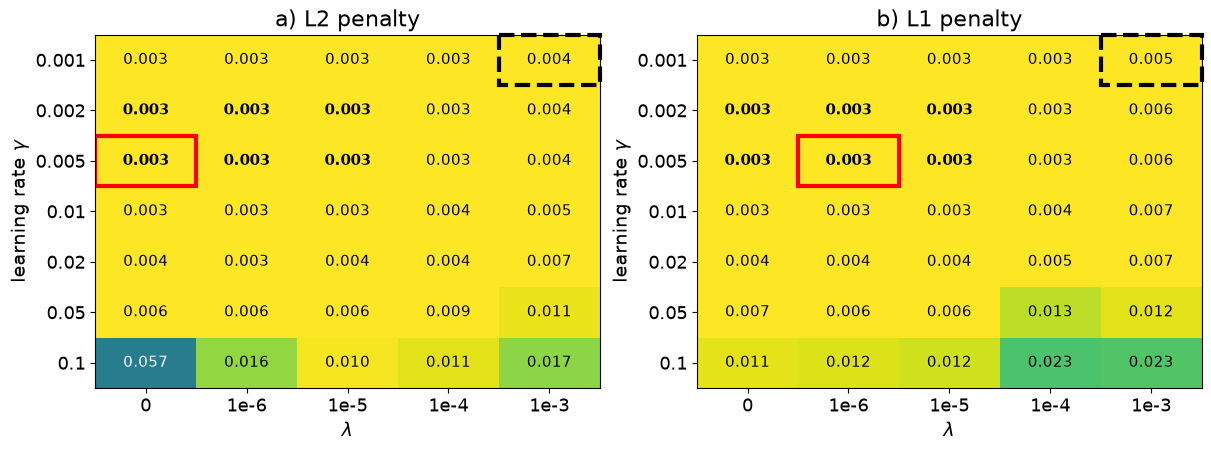

learning rate used from here on: gamma = 0.005
penalty used from here on: lambda = 1e-05


In [12]:
from sklearn.model_selection import GroupKFold, KFold

def cv_mse(x_tr, y_tr, hidden, gamma, lam, norm, k=5, epochs=200, groups=None, batch_size=1024):
    """k-fold CV MSE on the training data for one network setting (mean and standard error over the folds).
    If groups (the year of every row) is given, GroupKFold is used so that all rows of a year are in the same fold
    (no leakage between months / grid points of the same year). Otherwise a shuffled KFold on the rows is used.
    The validation MSE of a fold is averaged over the last 10 epochs, to remove jittering.
    batch_size: minibatch size of the training (large batches = far fewer, cheaper Python-level updates)."""
    scores = []
    splitter = GroupKFold(k).split(x_tr, groups=groups) if groups is not None \
        else KFold(k, shuffle=True, random_state=2026).split(x_tr)
    for tr, va in splitter:
        layers, act, der = setup_NN(x_tr.shape, y_tr.shape, hidden, activation_funcs=tanh, activation_ders=tanh_der, activation_output=identity, activation_output_der=identity_der)

        _, hist = train_penalised(layers, x_tr[tr], y_tr[tr], x_tr[va], y_tr[va],
                                  "adam", act, der, gamma, epochs, lam, norm, batch_size=batch_size)
        scores.append(hist[-10:, 2].mean())
    print(f"CV MSE for gamma={gamma}, lambda={lam}, norm={norm}: {np.mean(scores):.4f}")
    return float(np.mean(scores)), float(np.std(scores)) / np.sqrt(len(scores))   # mean and standard error, as cv_mse_nopen


# Load and preprocess data (gridinfo["groups_tr"] = year of every training row, used for GroupKFold)
x_tr, y_tr, x_te, y_te, gridinfo = load_SEB_data(return_gridinfo=True,season="winter",period="historical",split="blocks")
groups_tr = gridinfo["groups_tr"]
print("test years:", gridinfo["te_years"])

# Define network parameters
input_size = x_tr.shape[1]  # variables used for the equation
hidden_size = 50
output_size = y_tr.shape[1]  # Ts

# Print shapes 
print(f"Inputs shape: {x_tr.shape}")
print(f"Targets shape: {y_tr.shape}")


# Initialize model
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=tanh, activation_ders=tanh_der, activation_output=identity, activation_output_der=identity_der)

#Testing with JAX:
g_hand = backpropagation_batch(x_tr, layers0, activation_funcs, y_tr, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers0, x_tr, activation_funcs, y_tr)

# checking that the functions above agree with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax) ])


""" CV settings: the cost is ~ (rows) x (epochs) / batch_size x (number of grid cells) x k """
N_CV = 50_000       # random subsample of the training rows used for the hyperparameter search (None = all rows)
CV_BATCH = 1024     # minibatch size in the CV training
CV_EPOCHS = 100
""" END OF CV settings """

if N_CV is not None and N_CV < len(x_tr):
    sub = np.random.default_rng(2026).choice(len(x_tr), size=N_CV, replace=False)
    x_cv, y_cv, groups_cv = x_tr[sub], y_tr[sub], groups_tr[sub]
else:
    x_cv, y_cv, groups_cv = x_tr, y_tr, groups_tr
print(f"CV on {len(x_cv)} of {len(x_tr)} training rows, batch size {CV_BATCH}, {CV_EPOCHS} epochs")

#Looping through different lambdas and gammas
lam_grid = [0.0, 1e-6, 1e-5, 1e-4, 1e-3] # lambda = 0 is the unregularised network
gamma_grid = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1] # learning rates for Adam
lam_labels = [lam_label(l) for l in lam_grid]
norms = ["l2", "l1"]

grid_gl, grid_gl_se = {}, {} # norm -> (len(gamma_grid) x len(lam_grid)) arrays: CV MSE and its standard error
for norm in norms:
    res = np.array([[cv_mse(x_cv, y_cv, [50], g, lam, norm, epochs=CV_EPOCHS, groups=groups_cv, batch_size=CV_BATCH)
                     for lam in lam_grid] for g in gamma_grid]) # last axis: (mean, se) #groups_cv for groups
    grid_gl[norm], grid_gl_se[norm] = res[..., 0], res[..., 1]
    print(f"Done {norm} grid search: {grid_gl[norm].shape} (gamma x lambda)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for ax, norm, name in zip(axes, norms, ["a) L2 penalty", "b) L1 penalty"]):
    heatmap_nopen(ax, grid_gl[norm], gamma_grid, lam_labels, name, r"learning rate $\gamma$", r"$\lambda$", grid_se=grid_gl_se[norm],
                   label_fontsize=label_fontsize, title_fontsize=title_fontsize, tick_fontsize=tick_fontsize, annot_fontsize=legend_fontsize)
# black dashed frame to choose best according to 1 se rule 
    ax.add_patch(plt.Rectangle((lam_grid.index(1e-3) - 0.5, gamma_grid.index(0.001) - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--", clip_on=False))
# fig.suptitle("5-fold CV MSE, Adam, 1 hidden layer with 50 ReLU nodes (red = lowest, black = 1-se rule, bold = within 1 se)")
# plt.savefig("./figures/partd_lambda_gamma.png", dpi=500)
plt.show()

# One learning rate for the rest of part d): the best one over both grids (all lambda)
best_gamma = min(((grid_gl[n][i, j], gamma_grid[i]) for n in norms
                  for i in range(len(gamma_grid)) for j in range(len(lam_grid))))[1]
best_penalty = 1e-5  # the one chosen by the black dashed frame in the heatmaps above

print("learning rate used from here on: gamma =", best_gamma)
print("penalty used from here on: lambda =", best_penalty)



In [13]:
best_gamma = 0.002
best_penalty = 1e-5

### Pytorch NN

Inputs shape: torch.Size([449280, 9])
Targets shape: torch.Size([449280, 1])

Sample Inputs:
 tensor([[-8.8242e-02,  8.6080e-01, -1.4553e-01,  2.7366e-01, -3.2339e+00,
         -1.5108e+00, -1.6667e+00, -2.1962e-20,  1.4142e+00],
        [-7.8100e-02,  9.6115e-01,  7.0184e-02,  2.2809e-02, -3.2342e+00,
         -1.5630e+00, -1.6667e+00,  3.0851e-02,  1.4139e+00],
        [-8.7636e-02,  1.2602e+00,  1.7682e+00, -1.7503e+00, -3.2218e+00,
         -1.5126e+00, -1.6667e+00,  6.1687e-02,  1.4129e+00],
        [-9.4730e-02,  1.2222e+00,  3.8824e+00, -3.8518e+00, -3.2202e+00,
         -1.4329e+00, -1.6667e+00,  9.2494e-02,  1.4112e+00],
        [-9.4429e-02,  1.3583e+00,  4.5454e+00, -4.5803e+00, -3.2224e+00,
         -1.4761e+00, -1.6667e+00,  1.2326e-01,  1.4088e+00]])
Epoch [10/100], train MSE: 0.0019, test MSE: 0.0019
Epoch [20/100], train MSE: 0.0018, test MSE: 0.0017
Epoch [30/100], train MSE: 0.0016, test MSE: 0.0016
Epoch [40/100], train MSE: 0.0016, test MSE: 0.0015
Epoch [50/100], t

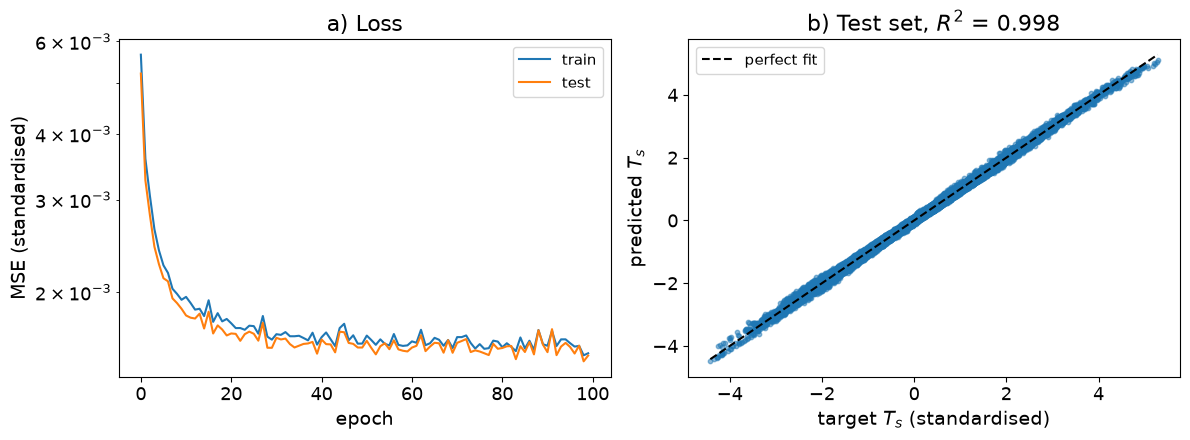

In [27]:
import torch
import torch.nn as nn
import torch.optim as optim

torch.set_num_threads(4)   # tiny matmuls: many threads only add overhead (check with torch.get_num_threads())

#The skeleton in this cell is provided by Claude, I have made some changes to fit the data and problem.

# Define the Neural Network
class SurfaceEnergyNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SurfaceEnergyNet, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.act = nn.Tanh()
        self.fc2 = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return x



# Main Training Loop: returns the model and the loss history
def train_network(model, inputs, targets, test_inputs=None, test_targets=None,
                  epochs=100, learning_rate=0.01, lam=0.0, norm="l2",batch_size=1024,seed=2026):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    gen = torch.Generator().manual_seed(seed)
    n = len(inputs)
    weights = [model.fc1.weight, model.fc2.weight]
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=gen)              # new shuffle every epoch
        xs, ys = inputs[perm], targets[perm]                 # one gather per epoch, batches are then cheap slices
        for start in range(0, n, batch_size):
            xb, yb = xs[start:start + batch_size], ys[start:start + batch_size]
            mse_loss = criterion(model(xb), yb)
            # Apply L1 or L2 regularization if specified
            if lam > 0:
                if norm == "l1":
                    loss = mse_loss + lam * sum(w.abs().sum() for w in weights)
                else:
                    loss = mse_loss + lam * sum(w.pow(2).sum() for w in weights)
            else:
                loss = mse_loss
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        # Both losses are evaluated on the full sets with the weights at the END of the epoch,
        # so the curves are comparable (the same "snapshot" for train and test)
        model.eval()
        with torch.no_grad():
            train_losses.append(criterion(model(inputs), targets).item())
            if test_inputs is not None:
                test_losses.append(criterion(model(test_inputs), test_targets).item())

        if (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], train MSE: {train_losses[-1]:.4f}"
                  + (f", test MSE: {test_losses[-1]:.4f}" if test_losses else ""))

        
       
    print("Training complete.")
    return model, train_losses, test_losses


# Example usage
if __name__ == "__main__":
    # Define network parameters
    input_size = len(FEATURE_NAMES)  # number of input features (6 SEB terms + extra features)
    hidden_size = 50
    output_size = 1  # Ts
    gamma = best_gamma  # Use the best gamma found from the grid search
    penalty = best_penalty # Use the best penalty found from the grid search

    # Initialize model
    model = SurfaceEnergyNet(input_size, hidden_size, output_size)

    """ INPUT for data """
    period = "historical"
    split = "blocks"
    season = "winter"
    """ END OF INPUTS """

    # Load and preprocess data (numpy), then convert to torch tensors for the PyTorch model only
    x_tr_np, y_tr_np, x_te_np, y_te_np = load_SEB_data(split=split, period=period, season=season)
    x_tr, y_tr, x_te, y_te = [torch.tensor(a, dtype=torch.float32)
                              for a in (x_tr_np, y_tr_np, x_te_np, y_te_np)]
    

    # Print shapes to verify
    print(f"Inputs shape: {x_tr.shape}")
    print(f"Targets shape: {y_tr.shape}")

    # Print a small sample
    print("\nSample Inputs:\n", x_tr[:5])
    batch = 1024   # ~8x fewer steps per epoch than 1024; lower it if the test MSE is worse than the own-NN/OLS

    # Train the model
    trained_model, train_losses, test_losses = train_network(
        model, x_tr, y_tr, x_te, y_te, learning_rate=gamma, lam=penalty, norm="l2", epochs=100, batch_size=batch)

    # Predictions on the test set (no gradients needed)
    trained_model.eval()
    with torch.no_grad():
        pred = trained_model(x_te).numpy().ravel()
    true = y_te.numpy().ravel()
    r2 = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)
    print(f"\nTest MSE = {np.mean((true - pred) ** 2):.4f}, R^2 = {r2:.3f}")

    # Plot: a) loss curves, b) predicted vs. target on the test set
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax1.semilogy(train_losses, label="train")
    ax1.semilogy(test_losses, label="test")
    ax1.set_xlabel("epoch", fontsize=label_fontsize)
    ax1.set_ylabel("MSE (standardised)", fontsize=label_fontsize)
    ax1.set_title("a) Loss", fontsize=title_fontsize)
    ax1.tick_params(axis="both", which="both", labelsize=tick_fontsize)
    ax1.legend(fontsize=legend_fontsize)

    ax2.scatter(true, pred, s=10, alpha=0.5)
    lims = [true.min(), true.max()]
    ax2.plot(lims, lims, "k--", label="perfect fit")
    ax2.set_xlabel("target $T_s$ (standardised)", fontsize=label_fontsize)
    ax2.set_ylabel("predicted $T_s$", fontsize=label_fontsize)
    ax2.set_title(f"b) Test set, $R^2$ = {r2:.3f}", fontsize=title_fontsize)
    ax2.tick_params(axis="both", which="both", labelsize=tick_fontsize)
    ax2.legend(fontsize=legend_fontsize)

    plt.tight_layout()

    plt.show()

In [18]:
# Why test is slightly better

# The test set is only 10 years, picked as 5 random 2-year blocks. If those years are less variable than the training average, for example fewer extreme winters, the MSE in standardised units comes out lower. A gap of a few percent is within the sampling noise of such a small set.
# You can check this with y_te.var() against y_tr.var(). If the test variance is below about 1, that explains most of the gap. R² for train and test is a fairer comparison than MSE.
# A different seed or block_len in load_SEB_data should shift the gap, and it may flip sign. If it does, the gap is a feature of that particular test draw and not a bug.
# Worth reporting in the project

# The small train/test difference shows that the NN is not overfitting. It also means that the NN's extra flexibility brings little over OLS, so compare their test MSE directly.
# The chronological and ssp585 tests are the ones that probe generalisation. In the blocks split every test year lies inside the training period, so it only tests interpolation.

print("Test variance:", y_te.var(), "train variance:", y_tr.var())

Test variance: 1.1854227764061598 train variance: 1.0


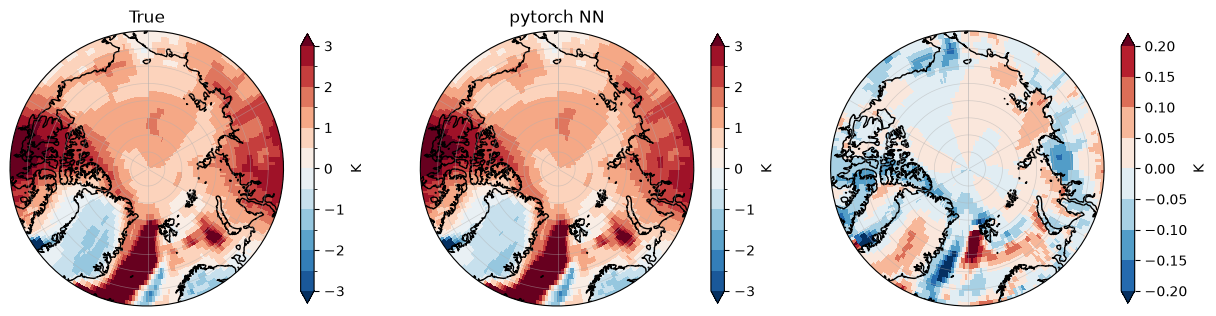

/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


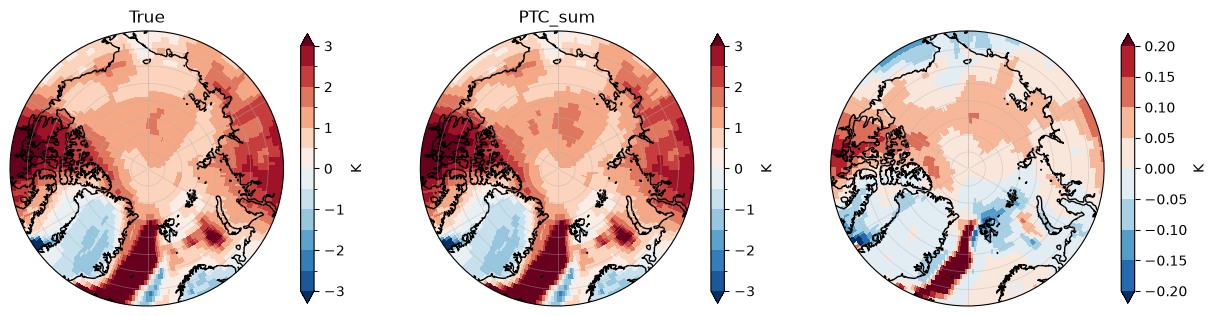

/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


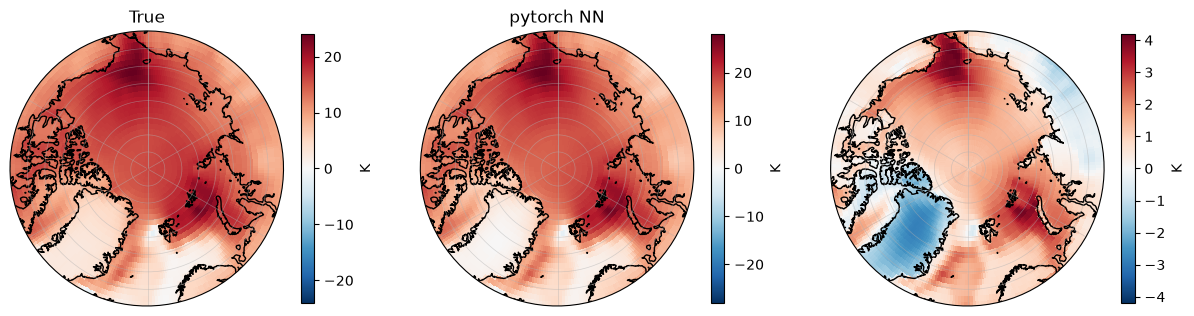

/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


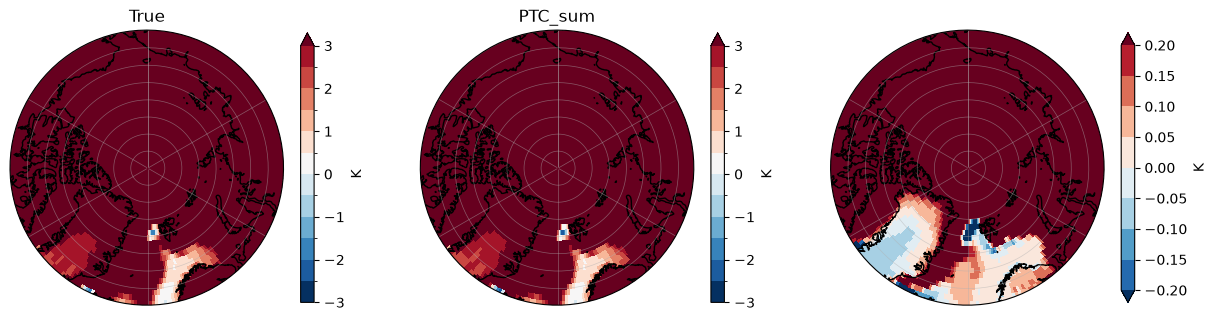

### Using the FFNN from Project 2

In [16]:
#TEST on the functions from project 2 (this is the same code as in project 2, to make sure no bug has appeared for project 3):
inputs = np.random.rand(1000, 4)

layers_b = create_layers_batch(4, [6, 5, 3])
layers_single = [(W.T, b) for W, b in layers_b]
out_batch = feed_forward_batch(inputs, layers_b, [ReLU, ReLU, sigmoid])
out_single = feed_forward(inputs[0], layers_single, [ReLU, ReLU, sigmoid])
print(out_batch.shape)
print("max difference on sample 0:", np.max(np.abs(out_batch[0] - out_single)))

#Testing the code with jax, both for single input and batch input
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers(network_input_size, layer_output_sizes)

xx = np.random.rand(network_input_size)
target = np.random.rand(4)

layer_grads = backpropagation(xx, layers, activation_funcs, target, activation_ders)

cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, xx, [sigmoid, ReLU], target)

# checking that the functions above agree with jax to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

inputs = np.random.rand(10, 2)
targets = np.random.rand(10, 4)
layers_b = create_layers_batch(2, [3, 4])

g_hand = backpropagation_batch(inputs, layers_b, activation_funcs, targets, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers_b, inputs, activation_funcs, targets)

for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax):
    print("dW", dW.shape, np.allclose(dW, dW_j), "   db", db.shape, np.allclose(db, db_j))

(1000, 3)
max difference on sample 0: 6.938893903907228e-18
[(True, True), (True, True)]
dW (2, 3) True    db (3,) True
dW (3, 4) True    db (4,) True


Inputs shape: (449280, 9)
Targets shape: (449280, 1)
[(True, True), (True, True)]

Test MSE = 0.0016, R^2 = 0.998
OLS test MSE = 0.0089, R^2 = 0.990


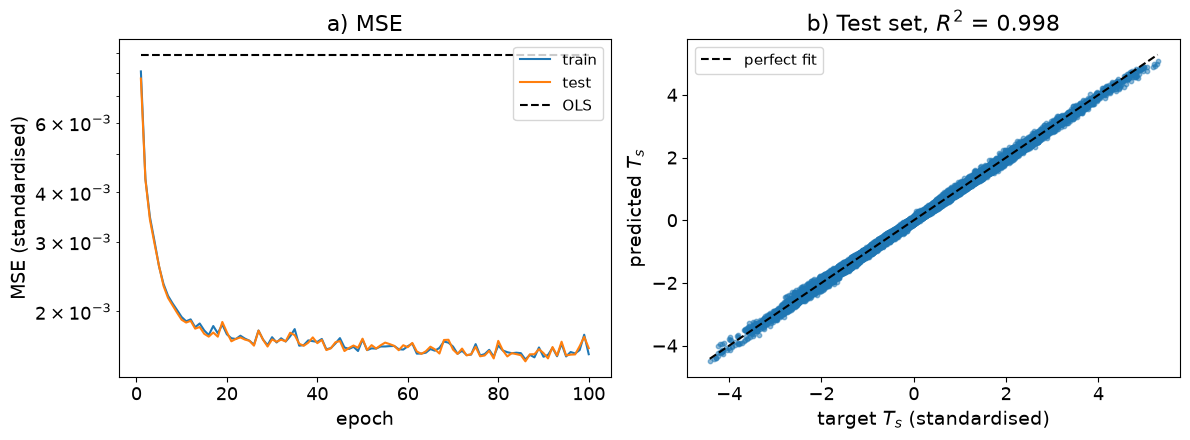

In [19]:
# Preparing data for training and testing
# Load and preprocess data
""" INPUT for data """
period = "historical"
split = "blocks"
season = "winter"
""" END OF INPUTS """


x_tr, y_tr, x_te, y_te = load_SEB_data(split=split, period=period, season=season)

# Define network parameters
input_size = x_tr.shape[1]  # variables used for the equation
hidden_size = 50
output_size = y_tr.shape[1]  # Ts

# Print shapes 
print(f"Inputs shape: {x_tr.shape}")
print(f"Targets shape: {y_tr.shape}")


# Initialize model
#model = SurfaceEnergyNet(input_size, hidden_size, output_size)
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=tanh, activation_ders=tanh_der, activation_output=identity, activation_output_der=identity_der)


#Testing with JAX:
g_hand = backpropagation_batch(x_tr, layers0, activation_funcs, y_tr, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers0, x_tr, activation_funcs, y_tr)

# checking that the functions above agree with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax) ])

# # Getting the noise floor on the test points
# sigma = 0.1
# noise_floor = np.mean((y_te - runge(x_te)) ** 2)
# print(f"noise level based on the test data: {noise_floor:.4f}  (sigma^2 = {sigma**2})")

# layers, hist  = train_penalised(layers0, x_tr, y_tr, x_te, y_te, step="adam", act=activation_funcs, act_der=activation_ders, gamma=0.001, epochs=500,lam=best_penalty, norm="l2") #currently using full-batch, not SGD
layers, hist = train_penalised(layers0, x_tr, y_tr, x_te, y_te, step="adam", act=activation_funcs,act_der=activation_ders, gamma=best_gamma, epochs=100,lam=best_penalty, norm="l2", batch_size=batch)
prediction = feed_forward_batch(x_te, layers, activation_funcs)

pred_sort = np.asarray(prediction).ravel() 
true = y_te.ravel()
r2 = 1 - np.sum((true - pred_sort) ** 2) / np.sum((true - true.mean()) ** 2)
print(f"\nTest MSE = {np.mean((true - pred_sort) ** 2):.4f}, R^2 = {r2:.3f}")


#Getting the OLS for comparison:

# Design matrix with intercept column
A_tr = np.hstack([x_tr, np.ones((x_tr.shape[0], 1))])
A_te = np.hstack([x_te, np.ones((x_te.shape[0], 1))])

theta_ols = closed_form(A_tr, y_tr)              # lam=0 -> plain OLS (fit on training set only)
pred_ols = A_te @ theta_ols                      # standardised prediction on the test set

mse_ols = np.mean((y_te - pred_ols) ** 2)
r2_ols = 1 - np.sum((y_te - pred_ols) ** 2) / np.sum((y_te - y_te.mean()) ** 2)
print(f"OLS test MSE = {mse_ols:.4f}, R^2 = {r2_ols:.3f}")

 

# Plot: a) loss curves, b) predicted vs. target on the test set
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.semilogy(hist[:,0],hist[:,1], label="train")
ax1.semilogy(hist[:,0],hist[:,2], label="test")
ax1.hlines(mse_ols, hist[0,0], hist[-1,0], colors="k", linestyles="--", label="OLS")
ax1.set_xlabel("epoch", fontsize=label_fontsize)
ax1.set_ylabel("MSE (standardised)", fontsize=label_fontsize)
ax1.set_title("a) MSE", fontsize=title_fontsize)
ax1.tick_params(axis="both", which="both", labelsize=tick_fontsize)
ax1.legend(fontsize=legend_fontsize)

ax2.scatter(true, pred_sort, s=10, alpha=0.5)
lims = [true.min(), true.max()]
ax2.plot(lims, lims, "k--", label="perfect fit")
ax2.set_xlabel("target $T_s$ (standardised)", fontsize=label_fontsize)
ax2.set_ylabel("predicted $T_s$", fontsize=label_fontsize)
ax2.set_title(f"b) Test set, $R^2$ = {r2:.3f}", fontsize=title_fontsize)
ax2.tick_params(axis="both", which="both", labelsize=tick_fontsize)
ax2.legend(fontsize=legend_fontsize)

plt.tight_layout()
plt.show()






### Random Forest

In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold


x_tr, y_tr, x_te, y_te, gridinfo = load_SEB_data(return_gridinfo=True, split=split, period=period, season=season)
groups_tr = gridinfo["groups_tr"]

# subsample for the search (same idea as N_CV for the NN)
N_RF = 50_000
sub = np.random.default_rng(2026).choice(len(x_tr), size=N_RF, replace=False)


# 1) Basic fit. ravel() because sklearn wants a 1D target (N,), not (N, 1)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=1/3,
                           oob_score=True, random_state=2026, n_jobs=-1)
rf.fit(x_tr, y_tr.ravel())

pred_rf = rf.predict(x_te)                           # standardised prediction, shape (N,)
t = y_te.ravel()
mse_rf = np.mean((t - pred_rf) ** 2)
r2_rf = 1 - np.sum((t - pred_rf) ** 2) / np.sum((t - t.mean()) ** 2)
print(f"RF test MSE = {mse_rf:.4f}, R^2 = {r2_rf:.3f}, OOB R^2 = {rf.oob_score_:.3f}")

# 2) Hyperparameters chosen by CV on the training set only (same folds as for the NN)
param_grid = {"min_samples_leaf": [1, 3, 5, 10],
              "max_depth": [1, 5, 10]}
gs = GridSearchCV(RandomForestRegressor(n_estimators=300, max_features=1/3, random_state=2026, n_jobs=-1),
                  param_grid, cv=GroupKFold(5, shuffle=True, random_state=2026),
                  scoring="neg_mean_squared_error")
gs.fit(x_tr[sub], y_tr[sub].ravel(), groups=groups_tr[sub])
print("best:", gs.best_params_, " CV MSE:", -gs.best_score_)
rf_best = gs.best_estimator_
pred_rf = rf_best.predict(x_te)

# 3) Feature importance (which input the forest uses)
names = FEATURE_NAMES
for n, imp in sorted(zip(names, rf_best.feature_importances_), key=lambda p: -p[1]):
    print(f"{n:9s} {imp:.3f}")



RF test MSE = 0.0250, R^2 = 0.971, OOB R^2 = 0.993
best: {'max_depth': 10, 'min_samples_leaf': 3}  CV MSE: 0.05673577063095392
LWCS      0.679
CRE       0.200
HSTORE    0.044
HFLUX     0.036
SAF       0.013
SWCS      0.012
sin_lon   0.006
cos_lon   0.005
lat       0.004


#### Temperature results

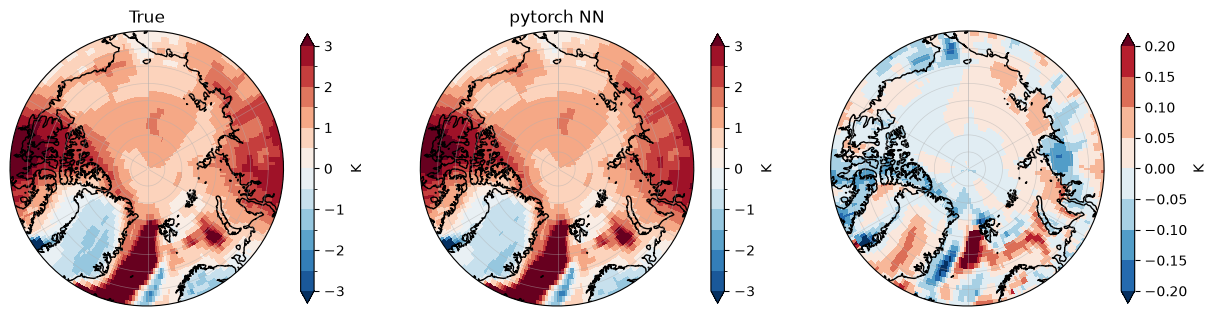

/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


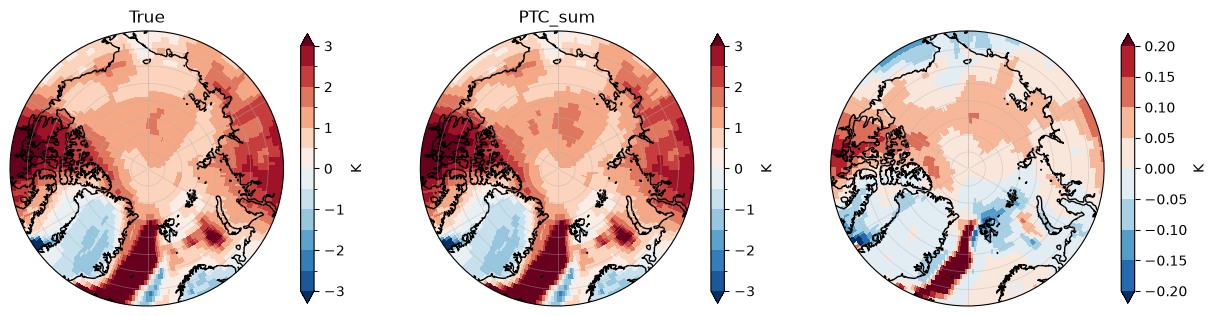

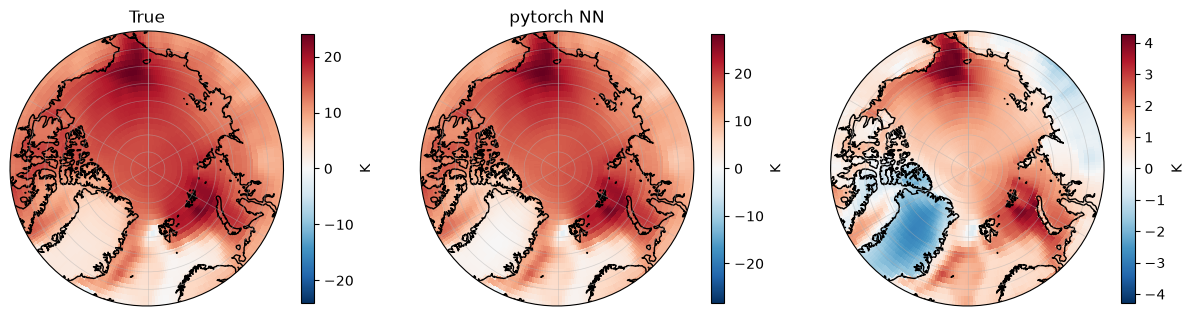

/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


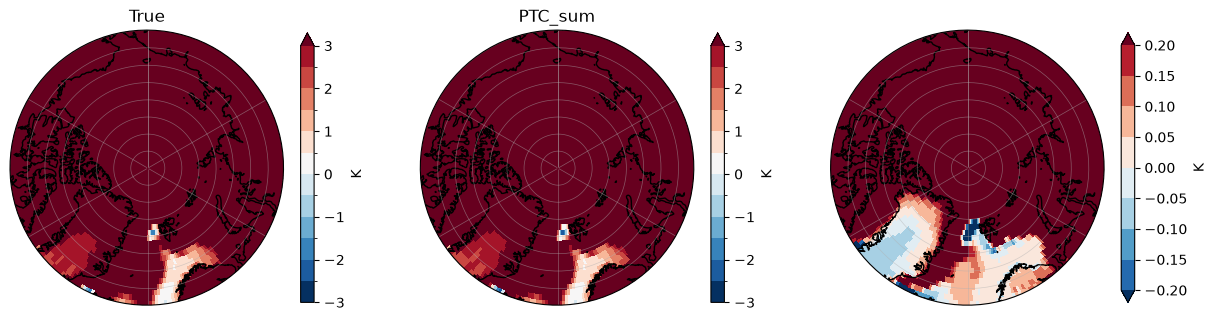

In [28]:

x_tr, y_tr, x_te, y_te, gridinfo = load_SEB_data(return_gridinfo=True,split=split,period=period,season=season)


pred_torch_da = to_grid(pred, gridinfo, "pytorch NN")
# pred_own_da   = to_grid(feed_forward_batch(x_te, layers, activation_funcs), gridinfo, "Own NN")
true_da       = to_grid(y_te, gridinfo, "True")

diff_da = pred_torch_da - true_da

levels = [-3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3]
difflev = [-0.2,-0.15, -0.1,-0.05, 0, 0.05, 0.1, 0.15, 0.2]
# circular boundary for a polar map
theta = np.linspace(0, 2 * np.pi, 100)
circle = mpath.Path(np.vstack([np.sin(theta), np.cos(theta)]).T * 0.5 + 0.5)

fig, axs = plt.subplots(1, 3, figsize=(15, 5),
                        subplot_kw={"projection": ccrs.NorthPolarStereo()})
for ax, da, levs in zip(axs, [true_da, pred_torch_da, diff_da],[levels,levels,difflev]):
    ax.set_extent([-180, 180, 66, 90], ccrs.PlateCarree())
    ax.set_boundary(circle, transform=ax.transAxes)
    da.mean("time").plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", levels=levs,
                         cbar_kwargs={"shrink": 0.7, "label": "K"})
    ax.coastlines()
    ax.gridlines(draw_labels=False, linewidth=0.5, alpha=0.5)
    ax.set_title(da.name)
plt.show()


def linear_temperature(season="summer", period = "historical"):

    ds, base = read_data(period=period)
    if season == "summer":
        ds_mean = ds.sel(time=base.time.dt.month.isin([6, 7, 8]))
        base_mean = base.sel(time=base.time.dt.month.isin([6, 7, 8])).mean(dim="time") 
    elif season == "winter":

        ds_mean = ds.sel(time=base.time.dt.month.isin([12, 1, 2]))
        base_mean = base.sel(time=base.time.dt.month.isin([12, 1, 2])).mean(dim="time") 

    ptc_temp = fhb.partial_temperature_fluxes(ds_mean,base_mean).sel(lat=slice(66, None)).load()

    return ptc_temp

ptc_temp = linear_temperature(season=season, period = period)

ptc_te = ptc_temp.sel(time=gridinfo["coords_te"]["time"])   # same times (and order) as true_da



difflin_da = ptc_te.PTC_sum - true_da
fig, axs = plt.subplots(1, 3, figsize=(15, 5),
                        subplot_kw={"projection": ccrs.NorthPolarStereo()})
for ax, da, levs in zip(axs, [true_da, ptc_te.PTC_sum, difflin_da],[levels,levels,difflev]):
    ax.set_extent([-180, 180, 66, 90], ccrs.PlateCarree())
    ax.set_boundary(circle, transform=ax.transAxes)
    da.mean("time").plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",levels=levs,
                         cbar_kwargs={"shrink": 0.7, "label": "K"})
    ax.coastlines()
    ax.gridlines(draw_labels=False, linewidth=0.5, alpha=0.5)
    ax.set_title(da.name)
plt.show()


#Testing it on future period with model trained on historical

x_tr_np, y_tr_np, x_te_np, y_te_np, gridinfo = load_SEB_data(return_gridinfo=True,split="chronological",period="ssp585",season=season)

x_tr, y_tr, x_te, y_te = [torch.tensor(a, dtype=torch.float32)
                              for a in (x_tr_np, y_tr_np, x_te_np, y_te_np)]
    
# Predictions on the test set (no gradients needed)
trained_model.eval()
with torch.no_grad():
    pred = trained_model(x_te).numpy().ravel()


pred_torch_da = to_grid(pred, gridinfo, "pytorch NN")
# pred_own_da   = to_grid(feed_forward_batch(x_te, layers, activation_funcs), gridinfo, "Own NN")
true_da       = to_grid(y_te_np, gridinfo, "True")

diff_da = pred_torch_da - true_da

# circular boundary for a polar map
theta = np.linspace(0, 2 * np.pi, 100)
circle = mpath.Path(np.vstack([np.sin(theta), np.cos(theta)]).T * 0.5 + 0.5)

fig, axs = plt.subplots(1, 3, figsize=(15, 5),
                        subplot_kw={"projection": ccrs.NorthPolarStereo()})
for ax, da in zip(axs, [true_da, pred_torch_da, diff_da]):
    ax.set_extent([-180, 180, 66, 90], ccrs.PlateCarree())
    ax.set_boundary(circle, transform=ax.transAxes)
    da.mean("time").plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",
                         cbar_kwargs={"shrink": 0.7, "label": "K"})
    ax.coastlines()
    ax.gridlines(draw_labels=False, linewidth=0.5, alpha=0.5)
    ax.set_title(da.name)
plt.show()



ptc_temp = linear_temperature(season=season, period = "ssp585")
ptc_te = ptc_temp.sel(time=gridinfo["coords_te"]["time"])   # same times (and order) as true_da


difflin_da = ptc_te.PTC_sum - true_da
fig, axs = plt.subplots(1, 3, figsize=(15, 5),
                        subplot_kw={"projection": ccrs.NorthPolarStereo()})
for ax, da, levs in zip(axs, [true_da, ptc_te.PTC_sum, difflin_da],[levels,levels,difflev]):
    ax.set_extent([-180, 180, 66, 90], ccrs.PlateCarree())
    ax.set_boundary(circle, transform=ax.transAxes)
    da.mean("time").plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",levels=levs,
                         cbar_kwargs={"shrink": 0.7, "label": "K"})
    ax.coastlines()
    ax.gridlines(draw_labels=False, linewidth=0.5, alpha=0.5)
    ax.set_title(da.name)
plt.show()





In [ ]:
#Compare the temperature results

ds, base = read_data()
ts = ds['ts'] - base['ts'].mean(dim="time")   # Surface temperature

target_tr = ts.sel(time=slice('1985-01-01', '2004-12-31')).values.reshape(-1, 1)
# Standardise both sets with the statistics of the TRAINING set
y_mean, y_std = target_tr.mean(), target_tr.std()

# Retrieving the absolute values 
pred_abs = pred * y_std + y_mean
y_te_abs = y_te * y_std + y_mean
prediction_abs = prediction * y_std + y_mean

pred_rf_abs = pred_rf * y_std + y_mean

pred_ols_abs = pred_ols * y_std + y_mean

plt.plot(pred_abs, label ="pytorch NN prediction")
plt.plot(prediction_abs, label ="Own NN prediction")
plt.plot(pred_rf_abs, label="Random forest")
plt.plot(pred_ols_abs, label="OLS")
plt.plot(y_te_abs, label ="True values")
plt.plot(np.arange(len(ptc_temp.PTC_sum.sel(time=slice("2005-01-01", "2014-12-31")))), ptc_temp.PTC_sum.sel(time=slice("2005-01-01", "2014-12-31")), label ="PTC sum")
plt.xticks(np.arange(0, len(y_te), 12), np.arange(2005, 2015))
plt.legend()
plt.xlabel("Year")
plt.ylabel("Surface temperature (K)")
plt.title("Comparison of predictions with true values")
plt.show()

In [ ]:
time = ptc_temp.PTC_sum.sel(time=slice("2005-01-01", "2014-12-31")).time

# np.asarray(...).ravel() turns torch/JAX/numpy arrays of shape (N, 1) into plain 1D numpy arrays
ds_cmp = xr.Dataset(
    data_vars={
        "pytorch NN": ("time", np.asarray(pred_abs).ravel()),
        "Own NN": ("time", np.asarray(prediction_abs).ravel()),
        "True values": ("time", np.asarray(y_te_abs).ravel()),
        "PTC sum": ("time", np.asarray(ptc_temp.PTC_sum.sel(time=time)).ravel()),
        "Random forest": ("time", np.asarray(pred_rf_abs).ravel()),
        "OLS": ("time", np.asarray(pred_ols_abs).ravel())
    },
    coords={"time": time},
)

# Monthly climatology (mean over the years 2005-2014)
ds_month = ds_cmp.groupby("time.month").mean()

for name in ds_month.data_vars:
    plt.plot(ds_month.month, ds_month[name], label=name)
plt.xticks(np.arange(1, 13))
plt.legend()
plt.xlabel("Month")
plt.ylabel("Surface temperature (K)")
plt.title("Comparison of predictions with true values")
plt.show()


### SHAP

In [ ]:

names = FEATURE_NAMES

# numpy copies (x_te/x_tr are reassigned between cells, so be explicit)
x_tr_np, y_tr_np, x_te_np, y_te_np = load_SEB_data()

# Subsample to keep SHAP cheap: the cost grows with (rows explained) x (background size) x 2^n_features (Exact)
N_SHAP, N_BG = 500, 50
x_sh = x_te_np[rng.choice(len(x_te_np), size=min(N_SHAP, len(x_te_np)), replace=False)]   # test rows to explain

# Use a background sample from the TRAINING data (more robust than a single zero row;
# zeros = training mean here, since inputs are standardised with training statistics)
bg_np = x_tr_np[rng.choice(len(x_tr_np), size=min(N_BG, len(x_tr_np)), replace=False)]

# Convert SHAP values from standardised units to Kelvin (y was standardised with y_std)
# y_std is defined in the "Temperature results" cell: y_std = target_tr.std()
def to_explanation(values, base, data):
    return shap.Explanation(values=values * y_std,
                            base_values=np.full(len(values), float(np.ravel(base)[0]) * y_std + y_mean),
                            data=data, feature_names=names)

# ---------- 1) PyTorch model: GradientExplainer ----------
trained_model.eval()
bg_t = torch.tensor(bg_np, dtype=torch.float32)
xsh_t = torch.tensor(x_sh, dtype=torch.float32)

expl_torch = shap.GradientExplainer(trained_model, bg_t)
sv_torch = np.asarray(expl_torch.shap_values(xsh_t)).reshape(len(x_sh), -1)   # (N_SHAP, n_features), drops trailing output axis
with torch.no_grad():
    base_torch = trained_model(bg_t).mean().item()
exp_torch = to_explanation(sv_torch, base_torch, x_sh)

# ---------- 2) Own NN: model-agnostic explainer ----------
# `layers` / `activation_funcs` = trained network from the own-NN cell
def own_nn_predict(X):
    return np.asarray(feed_forward_batch(np.asarray(X), layers, activation_funcs)).ravel()

# Exact Shapley values need 2^n_features coalitions (2048 for 11 features), hence the subsample
expl_own = shap.explainers.Exact(own_nn_predict, bg_np)
sv_own = expl_own(x_sh).values                         # (N_SHAP, n_features)
base_own = own_nn_predict(bg_np).mean()
exp_own = to_explanation(sv_own, base_own, x_sh)

# ---------- Plots ----------
for label, exp in [("PyTorch NN", exp_torch), ("Own NN", exp_own)]:
    shap.plots.waterfall(exp[0], show=False)          # one test sample
    plt.title(f"{label}: single test sample"); plt.show()

    shap.plots.beeswarm(exp, show=False)              # distribution per feature
    plt.title(label); plt.show()

# Global relative contribution: mean |SHAP| per input, as a fraction of the total
imp = {lab: np.abs(e.values).mean(axis=0) for lab, e in [("PyTorch NN", exp_torch), ("Own NN", exp_own)]}
x = np.arange(len(names)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
for i, (lab, v) in enumerate(imp.items()):
    ax.bar(x + (i - 0.5) * w, 100 * v / v.sum(), w, label=lab)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_ylabel("relative contribution (%) of mean |SHAP|"); ax.legend()
plt.tight_layout(); plt.show()



In [ ]:
def torch_predict(X):
    with torch.no_grad():
        return trained_model(torch.tensor(X, dtype=torch.float32)).numpy().ravel()

# same subsample (x_sh) as in the SHAP cell above
sv_torch_exact = shap.explainers.Exact(torch_predict, bg_np)(x_sh).values
print("torch GradientExplainer vs Exact:",
      np.abs(sv_torch).mean(0).round(3), np.abs(sv_torch_exact).mean(0).round(3))

# reference: SHAP of the linear fit is just coef * (x - mean)
sv_ols = (x_sh - bg_np.mean(0)) * theta_ols[:-1].ravel()
print("OLS    :", np.abs(sv_ols).mean(0).round(3))
print("own NN :", np.abs(sv_own).mean(0).round(3))

print(np.round(np.corrcoef(x_tr_np.T), 2))   # input collinearity


In [ ]:
groups = {"SAF": [0], "CRE": [1], "HSTORE+HFLUX+SWCS+LWCS": [2, 3, 4, 5]}
for lab, sv in [("torch", sv_torch_exact), ("own NN", sv_own), ("OLS", sv_ols)]:
    g = {k: np.abs(sv[:, idx].sum(1)).mean() for k, idx in groups.items()}
    print(lab, {k: round(v, 3) for k, v in g.items()})

print("cond(A_tr):", np.linalg.cond(A_tr))
print("OLS coefs :", theta_ols[:-1].ravel().round(2))        # large, opposite-signed -> collinearity
print("test MSE  : torch", np.mean((pred - y_te_np.ravel())**2),
      " own", np.mean((pred_sort - y_te_np.ravel())**2), " OLS", mse_ols)

In [ ]:
# Reference levels for the test MSE (y is standardised, so the mean predictor is about 1)
mean_mse = np.mean((y_te - y_tr.mean()) ** 2)          # always predict the training mean

# OLS on the 10 inputs (+ intercept), fitted on the training set only
A_tr = np.hstack([x_tr, np.ones((x_tr.shape[0], 1))])
A_te = np.hstack([x_te, np.ones((x_te.shape[0], 1))])
beta, *_ = np.linalg.lstsq(A_tr, y_tr, rcond=None)
ols_test_mse = np.mean((y_te - A_te @ beta) ** 2)

noise_floor = ols_test_mse    # keeps the later plotting cells working
print(f"test MSE, mean predictor: {mean_mse:.4f},  OLS: {ols_test_mse:.4f}")


print("epoch   GD 50x1: cost  test diff     GD 100x2: cost  test diff")
for e in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]:
    g = hist[e - 1]
    print("%5d     %7.2f   %.3f      " % (e, g[1], g[2]))

for name, L in [("GD 50x1, 1000 epochs", layers0)]:
    print("%-25s train cost %.3f   test cost %.3f"
          % (name,  float(cost_batch(L, x_tr, activation_funcs, y_tr)),
             float(cost_batch(L, x_te, activation_funcs, y_te))))

#Plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(hist[:, 0], hist[:, 1], label="1 hidden layer, 50 nodes")
# ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist[0, 0], xmax=hist[-1, 0], colors='k', linestyles='dashed', label="OLS test MSE / Noise floor")

ax1.set_xlabel("epoch", fontsize=label_fontsize); ax1.set_ylabel("MSE, training set", fontsize=label_fontsize); ax1.set_xscale("log")#; ax1.set_yscale("log")
ax1.set_title("a) MSE cost of training data", fontsize=title_fontsize)
ax1.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.semilogy(hist[:, 0], hist[:, 2], label="1 hidden layer, 50 nodes")
# ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist[0, 0], xmax=hist[-1, 0], colors='k', linestyles='dashed', label="OLS test MSE / Noise floor")
ax2.set_xlabel("epoch", fontsize=label_fontsize); ax2.set_ylabel("MSE, test set", fontsize=label_fontsize); ax2.set_xscale("log")
ax2.set_title("b) MSE cost of test data",fontsize=title_fontsize)
ax2.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.legend(fontsize=legend_fontsize,loc="best")

# fig.suptitle("Comparison of hidden layers and nodes")
plt.tight_layout()
# plt.savefig("./figures/NN_50x1_100x2.png", dpi=500)
plt.show()

# print("MSE train OLS:", MSE(OLS_regression(x_tr, y_tr),y_tr))
# print("MSE test OLS:", MSE(OLS_regression(x_te, y_te),y_te))

In [ ]:
# Load CMIP6 data
def load_cmip6_data():
    """Returns numpy arrays (x_tr, y_tr, x_te, y_te) with shapes (N, 10) and (N, 1).
    Works directly with the own NN code (numpy/JAX); use torch.tensor(...) for the PyTorch model."""
    ds, base = read_data()
    # Extract variables and preprocess them
    rsds = global_avg(ds['rsds']) - global_avg(base['rsds']).mean(dim="time")  # Downwelling shortwave radiation
    rlds = global_avg(ds['rlds']) - global_avg(base['rlds']).mean(dim="time")  # Downwelling longwave radiation
    rlns = global_avg(ds['rlns']) - global_avg(base['rlns']).mean(dim="time")  # Net longwave radiation
    hfss = global_avg(ds['hfss']) - global_avg(base['hfss']).mean(dim="time")   # Sensible heat flux
    hfls = global_avg(ds['hfls']) - global_avg(base['hfls']).mean(dim="time")   # Latent heat flux
    rsuscs = global_avg(ds['rsuscs']) - global_avg(base['rsuscs']).mean(dim="time")  # Upwelling shortwave radiation clear-sky
    rsdscs = global_avg(ds['rsdscs']) - global_avg(base['rsdscs']).mean(dim="time")  # Downwelling shortwave radiation clear-sky
    rlnscs = global_avg(ds['rlnscs']) - global_avg(base['rlnscs']).mean(dim="time")  # Net longwave radiation clear-sky
    rldscs = global_avg(ds['rldscs']) - global_avg(base['rldscs']).mean(dim="time")  # Net longwave radiation clear-sky
    rlus = global_avg(ds['rlus']) - global_avg(base['rlus']).mean(dim="time")  # Upwelling longwave radiation

    ts = global_avg(ds['ts']) - global_avg(base['ts']).mean(dim="time")   # Surface temperature

    # Stack inputs and normalize
    input_tr = np.stack([rsds.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlds.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlns.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       hfss.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       hfls.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rsuscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rsdscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlnscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rldscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlus.sel(time=slice('1985-01-01', '2004-12-31')).values], axis=1)

    input_te = np.stack([rsds.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlds.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlns.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       hfss.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       hfls.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rsuscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rsdscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlnscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rldscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlus.sel(time=slice('2005-01-01', '2014-12-31')).values], axis=1)

    # Targets as numpy arrays of shape (N, 1)
    target_tr = ts.sel(time=slice('1985-01-01', '2004-12-31')).values.reshape(-1, 1)
    target_te = ts.sel(time=slice('2005-01-01', '2014-12-31')).values.reshape(-1, 1)

    # Standardise both sets with the statistics of the TRAINING set
    x_mean, x_std = input_tr.mean(axis=0), input_tr.std(axis=0)
    y_mean, y_std = target_tr.mean(), target_tr.std()

    input_tr = (input_tr - x_mean) / x_std
    input_te = (input_te - x_mean) / x_std
    target_tr = (target_tr - y_mean) / y_std
    target_te = (target_te - y_mean) / y_std

    return input_tr, target_tr, input_te, target_te

### project 2 stuff:

In [ ]:
# Your code for part d) here
###################################
# add the L1 / L2 penalties to the network code of part b)
###################################

# same data, split and scaling as in part b)
#x_tr, x_te, y_tr, y_te = prepare_data(x, y)

def check_gradient_jax(x_tr, y_tr, norm, lam=1e-2): #from project 2, just changed the build_net function to the setup_NN function
    """Largest difference between backprop and jax.grad of the full penalised cost."""
    layers, act, der = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)

    g_hand = backprop_penalised(x_tr, layers, act, y_tr, der, lam, norm)
    # jax.grad differentiates with respect to the list of (W, b) pairs and returns the same structure
    g_jax = jax.grad(lambda L: penalised_cost_jax(L, x_tr, y_tr, act, lam, norm))(layers)
    return max(max(np.max(np.abs(dW - np.asarray(dW_j))), np.max(np.abs(db - np.asarray(db_j))))
               for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax))



for norm in ["l2", "l1"]:
    print(f"norm = {norm}: max |JAX - backprop| = {check_gradient_jax(x_tr, y_tr, norm):.1e}")

In [ ]:
###################################
# final training, comparison with OLS / Ridge / Lasso
###################################
seeds = [2026]
# seeds = range(10) #for a mean +- spread over several runs (10 times slower)

# 1x50 network chosen with the 1-se rule, without penalty and with L2 / L1 (set your lambdas)
choice["unpenalised_1se"] = ([50], 0.0, "l2", None)
choice["l2_1se"] = ([50], 1e-3, "l2", None)
choice["l1_1se"] = ([50], 1e-3, "l1", None)

x_mean, x_std = x_tr_raw.mean(), x_tr_raw.std() # the same scaling as in prepare_data
xx = np.linspace(-1, 1, 400) # dense grid for plotting the fits
xx_std = ((xx - x_mean) / x_std).reshape(-1, 1)

final = {} # name -> dict with the results
for name, (hid, lam, norm, _) in choice.items():
    tr_err, te_err = [], []
    for seed in seeds:
        layers, act, der = build_net(hid, seed=seed)
        if '1se' in name:
            best_gamma = 0.001
        else:
            best_gamma = 0.005
        layers, hist = train_penalised(layers, x_tr, y_tr, x_te, y_te, "adam", act, der,
                                       best_gamma, 200, lam, norm, seed=seed)
        tr_err.append(hist[-1, 1]) # MSE after the last epoch
        te_err.append(hist[-1, 2])
        if seed == seeds[0]: # keep the fit of the first run for the plot
            curve = feed_forward_batch(xx_std, layers, act)[:, 0]
    final[name] = dict(train=np.mean(tr_err), test=np.mean(te_err), test_std=np.std(te_err), curve=curve)

### Table
print(f"\n{'model':30s} {'settings':34s} {'train MSE':>9s} {'test MSE':>9s}")
rows = []
for kind in ["OLS", "Ridge", "Lasso"]:
    cv_err, d, lam, tr_m, te_m = baseline[kind]
    s = f"degree {d}" + ("" if kind == "OLS" else f", lambda={lam:.0e}")
    rows.append((kind + " (polynomial)", s, tr_m, te_m, 0.0))
for name, label in [("unpenalised", "NN, no penalty"), ("l2", "NN + L2"), ("l1", "NN + L1"),
                    ("unpenalised_1se", "NN 1x50, no penalty"), ("l2_1se", "NN 1x50 + L2"), ("l1_1se", "NN 1x50 + L1")]:
    hid, lam, norm, _ = choice[name]
    s = f"{len(hid)}x{hid[0]}, lambda={lam:g}, gamma={best_gamma}"
    rows.append((label, s, final[name]["train"], final[name]["test"], final[name]["test_std"]))
for r in rows:
    spread = f" +- {r[4]:.4f}" if r[4] > 0 else "" # the spread only exists with several seeds
    print(f"{r[0]:30s} {r[1]:34s} {r[2]:9.4f} {r[3]:9.4f}{spread}")
print(f"{'noise level of test points':30s} {'':34s} {'':9s} {noise_floor:9.4f}")

### Figure: (a) fits of the regularised models, (b) test MSE of all models
fig, ax = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)

# ax[0].plot(xx, runge(xx), "k:", label="Runge function")
ax[0].scatter(x_te_raw, y_te_raw, s=14, color="#A0720E", label="test data")
ax[0].plot(xx, baseline_models["Ridge"].predict(xx.reshape(-1, 1)), color=RED, alpha=0.7, ls="--", label="Ridge")
ax[0].plot(xx, baseline_models["Lasso"].predict(xx.reshape(-1, 1)), color=GREEN, alpha=0.7, ls="--", label="Lasso")
ax[0].plot(xx, final["l2"]["curve"], color=RED, ls="-", lw=1, alpha=1, label="NN + L2")
ax[0].plot(xx, final["l1"]["curve"], color=GREEN, ls="-", lw=1, alpha=1, label="NN + L1")
ax[0].plot(xx, final["l2_1se"]["curve"], color=RED, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L2")
ax[0].plot(xx, final["l1_1se"]["curve"], color=GREEN, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L1")
ax[0].set_xlabel("x", fontsize=label_fontsize); ax[0].set_ylabel("y", fontsize=label_fontsize); ax[0].legend(fontsize=legend_fontsize)
ax[0].set_title("a) fits of the regularised models", fontsize=title_fontsize)
ax[0].tick_params(axis="both", which="major", labelsize=tick_fontsize)

labels = [r[0] for r in rows]
bars = ax[1].bar(range(len(rows)), [r[3] for r in rows], yerr=[r[4] for r in rows],
                 color=[GREY, GREY, GREY, BLUE, RED, GREEN, BLUE, RED, GREEN], capsize=3) 
for b in bars[6:]:
    b.set_hatch("//") # hatched = the 1x50 network chosen with the 1-se rule
ax[1].axhline(noise_floor, color="k", ls=":", label="noise level of the test points")
ax[1].set_xticks(range(len(rows)))
ax[1].set_xticklabels([l.replace(" (polynomial)", "\n(polynomial)") for l in labels], rotation=40, ha="right", fontsize=tick_fontsize)
ax[1].set_ylabel("test MSE", fontsize=label_fontsize); ax[1].legend(fontsize=legend_fontsize)
ax[1].set_title("b) test MSE", fontsize=title_fontsize)
ax[1].tick_params(axis="both", which="major", labelsize=tick_fontsize)
# plt.savefig("./figures/partd_comparison.png", dpi=500)
plt.show()